In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# Check pandas version
print(pd.__version__)

# Check numpy version
print(np.__version__)

# Check matplotlib version
print(plt.matplotlib.__version__)

3.0.3
2.4.6
3.11.0


In [11]:
import pandas as pd

df = pd.read_csv(r"‪C:\Users\A\Downloads\ecommerce_sales.csv")
df

OSError: [Errno 22] Invalid argument: '\u202aC:\\Users\\A\\Downloads\\ecommerce_sales.csv'

In [12]:
df = pd.read_csv(r"C:\Users\A\Downloads\ecommerce_sales.csv")
df.head()

,order_id,customer_name,city,product_name,category,quantity,unit_price,order_date
0,2001,Arjun,Jaipur,Mobile,Electronics,1,25000,2026-03-12
1,2002,Neha,Delhi,Keyboard,Accessories,2,1500,2026-01-27
2,2003,Arjun,Jaipur,Jeans,Fashion,1,2200,2026-06-01
3,2004,Rohit,Pune,Laptop,Electronics,1,55000,2026-01-24
4,2005,Neha,Delhi,Keyboard,Accessories,5,1500,2026-06-04


In [13]:
df.shape

(100, 8)

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   order_id       100 non-null    int64
 1   customer_name  100 non-null    str  
 2   city           100 non-null    str  
 3   product_name   100 non-null    str  
 4   category       100 non-null    str  
 5   quantity       100 non-null    int64
 6   unit_price     100 non-null    int64
 7   order_date     100 non-null    str  
dtypes: int64(3), str(5)
memory usage: 10.0 KB


In [16]:
df.isnull().sum()

order_id         0
customer_name    0
city             0
product_name     0
category         0
quantity         0
unit_price       0
order_date       0
dtype: int64

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.describe()


,order_id,quantity,unit_price
count,100.000000,100.000000,100.000000
mean,2050.500000,2.830000,11430.000000
std,29.011492,1.497844,16361.265541
min,2001.000000,1.000000,700.000000
25%,2025.750000,2.000000,1500.000000
50%,2050.500000,2.000000,2200.000000
75%,2075.250000,4.000000,19750.000000
max,2100.000000,5.000000,55000.000000


In [21]:
df["revenue"] = df["quantity"] * df["unit_price"]

In [20]:
df.head()

,order_id,customer_name,city,product_name,category,quantity,unit_price,order_date,revenue
0,2001,Arjun,Jaipur,Mobile,Electronics,1,25000,2026-03-12,25000
1,2002,Neha,Delhi,Keyboard,Accessories,2,1500,2026-01-27,3000
2,2003,Arjun,Jaipur,Jeans,Fashion,1,2200,2026-06-01,2200
3,2004,Rohit,Pune,Laptop,Electronics,1,55000,2026-01-24,55000
4,2005,Neha,Delhi,Keyboard,Accessories,5,1500,2026-06-04,7500


In [22]:
total_sales = df["revenue"].sum()

print("Total Sales:", total_sales)

Total Sales: 3282800


In [23]:
city_sales = df.groupby("city")["revenue"].sum()

print(city_sales)

city
Chandigarh    648400
Delhi         863400
Gurgaon       365900
Jaipur        179400
Lucknow        93100
Mumbai        351600
Noida         658700
Pune          122300
Name: revenue, dtype: int64


In [25]:
category_sales = df.groupby("category")["revenue"].sum()

print(category_sales)

category
Accessories     276000
Electronics    2867000
Fashion         139800
Name: revenue, dtype: int64


In [26]:
product_quantity = df.groupby("product_name")["quantity"].sum()

print(product_quantity)

product_name
Headphones    26
Jeans         32
Keyboard      42
Laptop        28
Mobile        43
Mouse         30
Shoes         17
T-Shirt       23
Tablet        14
Watch         28
Name: quantity, dtype: int64


In [27]:
top_products = df.groupby("product_name")["quantity"].sum().sort_values(ascending=False).head(5)

print(top_products)

product_name
Mobile      43
Keyboard    42
Jeans       32
Mouse       30
Watch       28
Name: quantity, dtype: int64


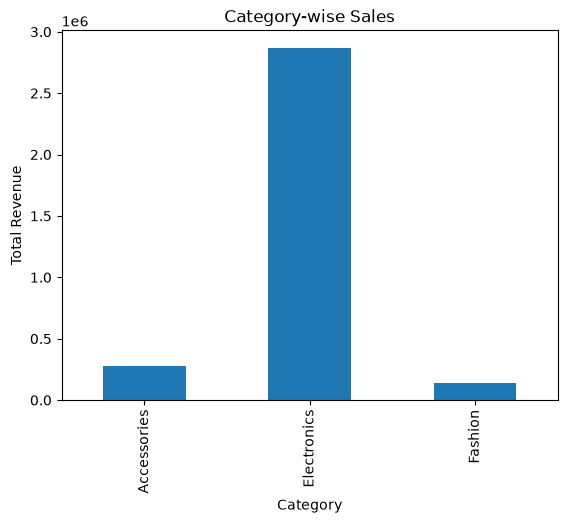

In [28]:
category_sales.plot(kind="bar")

plt.title("Category-wise Sales")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.show()

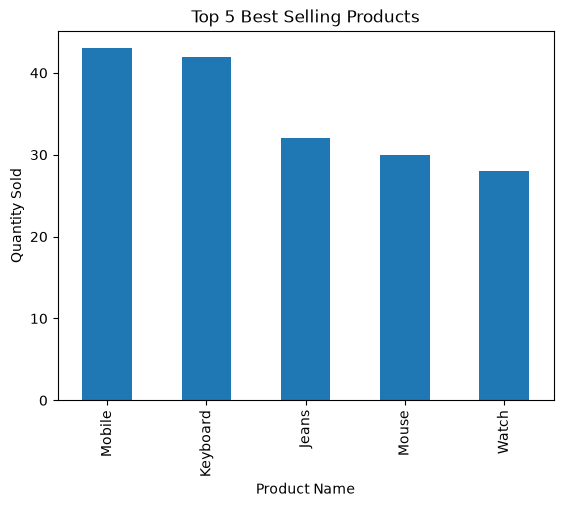

In [29]:
top_products.plot(kind="bar")

plt.title("Top 5 Best Selling Products")
plt.xlabel("Product Name")
plt.ylabel("Quantity Sold")
plt.show()

In [30]:
product_revenue = df.groupby("product_name")["revenue"].sum()

product_revenue = product_revenue.sort_values(ascending=False)

print(product_revenue)

product_name
Laptop        1540000
Mobile        1075000
Tablet         252000
Watch          140000
Jeans           70400
Keyboard        63000
Headphones      52000
Shoes           51000
Mouse           21000
T-Shirt         18400
Name: revenue, dtype: int64


In [34]:
customer_sales = df.groupby("customer_name")["revenue"].sum()

customer_sales = customer_sales.sort_values(ascending=False)

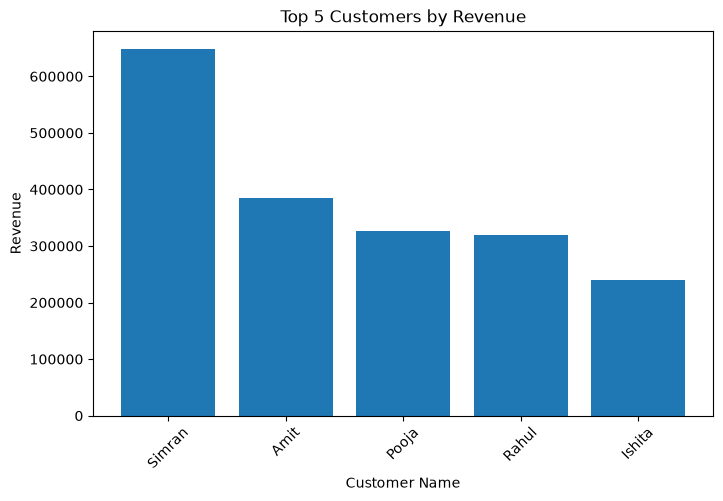

In [35]:
plt.figure(figsize=(8, 5))
plt.bar(customer_sales.index[:5], customer_sales.values[:5])

plt.title("Top 5 Customers by Revenue")
plt.xlabel("Customer Name")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()